| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../18_HPC_COMPUTACION_CIENTIFICA/18_1_Performance.ipynb) | [⏩](../18_HPC_COMPUTACION_CIENTIFICA/18_3_Parallel_computing.ipynb) |

# 18.2 GPU PARA SCIENTIFIC MACHINE LEARNING

Una GPU ejecuta muchas operaciones sobre datos en paralelo. Es útil cuando hay suficiente trabajo regular para amortizar lanzamientos y movimiento de memoria, pero una tarea pequeña puede ser más rápida en CPU. Vamos a usar PyTorch para estudiar dispositivos, medición, precisión y diferenciación de un modelo físico.

**El cuaderno funciona también en CPU.** Si CUDA no está disponible, todas las demostraciones se ejecutan en CPU y las gráficas se etiquetan como mediciones de CPU. No se inventan tiempos de GPU ni se infiere una aceleración no observada. Requisitos: PyTorch, NumPy y Matplotlib; no se necesitan datos externos.

**Objetivos.** Mover datos de forma explícita, sincronizar mediciones, verificar precisión y aplicar operaciones por lotes a un problema de difusión y a inferencia de parámetros.

## 1. Arquitectura y granularidad

Una CPU está diseñada para tareas diversas y acceso flexible; una GPU ofrece muchos recursos para operaciones paralelas regulares. Una multiplicación matricial grande tiene mucha reutilización de datos y suele ser un buen candidato. Un bucle con muchas ramas o transferencias de escalares puede no aprovecharla.

El tiempo extremo a extremo incluye preparar entradas, transferir, ejecutar kernels y recuperar resultados. Separarlo del tiempo de un kernel ayuda a entender la aplicación, pero ambas cifras deben identificarse claramente.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from time import perf_counter
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
torch.manual_seed(182)
torch.set_num_threads(2)
hay_cuda = torch.cuda.is_available()
device = torch.device("cuda" if hay_cuda else "cpu")
etiqueta = torch.cuda.get_device_name(0) if hay_cuda else "CPU (CUDA no disponible)"
print("PyTorch:", torch.__version__)
print("Dispositivo usado:", etiqueta)
x_cpu = torch.linspace(0, 1, 5, dtype=torch.float64)
x_device = x_cpu.to(device)
print("Valores:", x_device.detach().cpu().numpy())
print("dtype y device:", x_device.dtype, x_device.device)

PyTorch: 2.14.1+cpu
Dispositivo usado: CPU (CUDA no disponible)
Valores: [0.   0.25 0.5  0.75 1.  ]
dtype y device: torch.float64 cpu


## 2. Tensores, dispositivo y tipo numérico

Para operar entre tensores, normalmente deben estar en dispositivos compatibles. `x.to(device)` puede implicar una copia; `x.cpu().numpy()` devuelve datos a CPU para Matplotlib. No conviene hacer esa transferencia dentro de cada pequeña operación del solver.

El tipo `float32` usa cuatro bytes por valor y `float64` ocho. Float64 no es automáticamente lento en todas las GPUs, ni float32 automáticamente suficiente para física. La decisión depende de hardware, condicionamiento y tolerancia científica. Los gradientes pueden amplificar errores numéricos que apenas se ven en la solución directa.

La configuración de dos hilos de CPU limita el tamaño de esta demostración y hace más predecible su ejecución; el cuaderno no busca caracterizar al máximo todos los núcleos de la máquina.

## 3. Medir kernels asíncronos correctamente

CUDA puede devolver control a Python antes de terminar el cálculo. Medir solo la llamada registra parcialmente el lanzamiento. Para una medición por reloj de pared sincronizaremos **antes y después** de la operación. El calentamiento queda fuera porque inicialización, compilación o caché pueden distorsionar el primer intento.

Los datos de entrada permanecerán en el dispositivo durante el benchmark de kernel. Más adelante veremos por separado una medición que incluye transferencias. Los tamaños son moderados para que el cuaderno pueda estudiarse en un portátil.

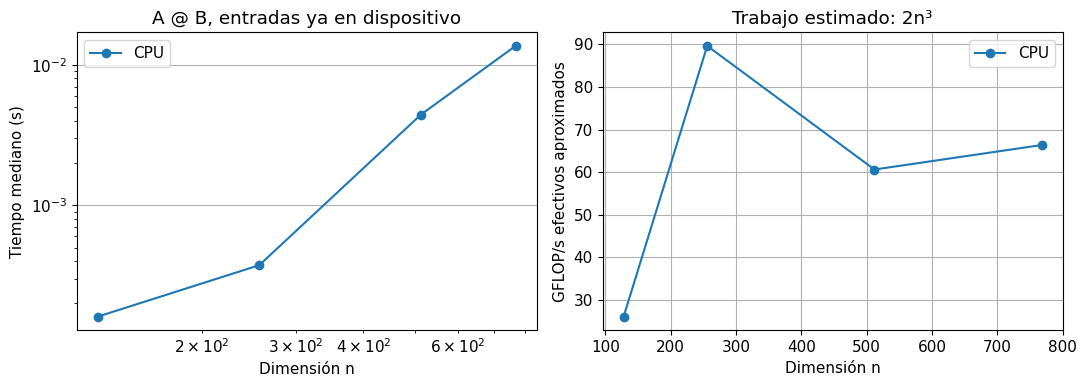

In [2]:
def sincronizar(dev):
    if dev.type == "cuda":
        torch.cuda.synchronize(dev)

def medir_torch(func, dev, repeticiones=5):
    func(); sincronizar(dev)
    tiempos = []
    for _ in range(repeticiones):
        sincronizar(dev); ini = perf_counter()
        resultado = func(); sincronizar(dev)
        tiempos.append(perf_counter()-ini)
    return float(np.median(tiempos))

tamanos = [128, 256, 512, 768]
resultados = {}
dispositivos = [torch.device("cpu")] + ([device] if hay_cuda else [])
for dev in dispositivos:
    nombre = "CUDA" if dev.type == "cuda" else "CPU"
    tiempos = []
    for n in tamanos:
        a = torch.randn(n, n, device=dev, dtype=torch.float32)
        b = torch.randn(n, n, device=dev, dtype=torch.float32)
        with torch.no_grad():
            tiempos.append(medir_torch(lambda: a @ b, dev))
    resultados[nombre] = tiempos
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nombre, tiempos in resultados.items():
    axes[0].loglog(tamanos, tiempos, "o-", label=nombre)
    flops = 2*np.array(tamanos, dtype=float)**3
    axes[1].plot(tamanos, flops/np.array(tiempos)/1e9, "o-", label=nombre)
axes[0].set(xlabel="Dimensión n", ylabel="Tiempo mediano (s)", title="A @ B, entradas ya en dispositivo")
axes[1].set(xlabel="Dimensión n", ylabel="GFLOP/s efectivos aproximados", title="Trabajo estimado: 2n³")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 4. Qué concluyen estas mediciones

Los GFLOP/s se calculan con el conteo aproximado $2n^3$, no son una medida independiente del hardware. Comparan ese kernel y tamaño. La GPU puede usar estrategias de multiplicación o formatos internos distintos según configuración; el benchmark no valida todavía su error científico.

Si solo aparece una curva CPU, no hemos comparado CPU y GPU. Si hay dos, tampoco podemos generalizar la razón a un solver con ramas, una PINN con derivadas de segundo orden o un entrenamiento dominado por carga de datos. Las transferencias están excluidas y la reserva de memoria de entradas ocurre antes.

## 5. Transferencias y costo extremo a extremo

Copiar CPU→GPU y GPU→CPU tiene latencia y costo proporcional a bytes. Para pequeñas tareas, agrupar operaciones evita pagar ese costo una y otra vez. En CPU, `.to('cpu')` puede devolver el mismo objeto: no es una transferencia real y así se etiquetará.

Mediremos una función que empieza con arreglos en CPU, lleva ambos al dispositivo, multiplica y devuelve el resultado. Esta medición incluye esos pasos, a diferencia del benchmark anterior.

In [3]:
n = 512
a_host = torch.randn(n, n); b_host = torch.randn(n, n)
a_local, b_local = a_host.to(device), b_host.to(device)

def extremo_a_extremo():
    aa, bb = a_host.to(device), b_host.to(device)
    return (aa @ bb).cpu()

with torch.no_grad():
    t_kernel = medir_torch(lambda: a_local @ b_local, device)
    t_total = medir_torch(extremo_a_extremo, device)
print("Kernel con entradas locales (s):", t_kernel)
print("Preparar, ejecutar y devolver (s):", t_total)
print("Datos de entrada (MiB):", (a_host.numel()+b_host.numel())*a_host.element_size()/2**20)
if not hay_cuda:
    print("Modo CPU: .to(cpu) no representa una transferencia entre CPU y GPU.")

Kernel con entradas locales (s): 0.002911518000473734
Preparar, ejecutar y devolver (s): 0.002480275001289556
Datos de entrada (MiB): 2.0
Modo CPU: .to(cpu) no representa una transferencia entre CPU y GPU.


## 6. Precisión: cancelación y condicionamiento

Una máquina representa un conjunto finito de números. Para float32, la separación relativa cerca de uno es de orden $10^{-7}$; para float64, de orden $10^{-16}$. Si restamos números cercanos, podemos perder cifras relevantes.

Para $f(h)=(e^h-1)/h$, el límite cuando $h\to0$ es uno. Evaluar `exp(h)-1` puede cancelar; `expm1(h)` está diseñada para calcular esa diferencia con mayor precisión. No arreglamos un algoritmo inestable únicamente cambiando de dispositivo: primero revisamos su formulación.

Epsilon float32: 1.1920928955078125e-07
Epsilon float64: 2.220446049250313e-16


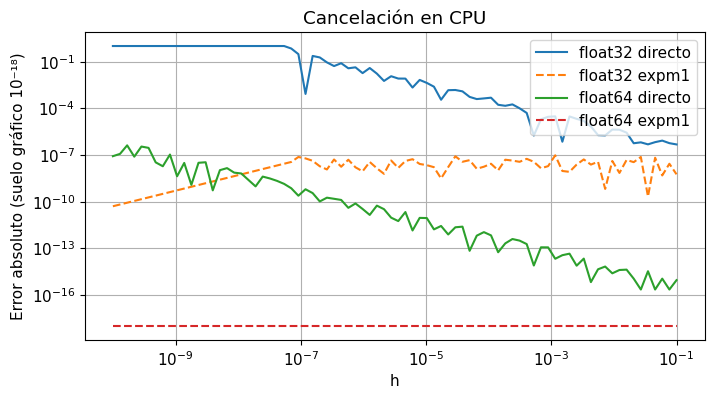

In [4]:
hs = np.logspace(-10, -1, 80)
fig, ax = plt.subplots()
for dtype, nombre in [(torch.float32, "float32"), (torch.float64, "float64")]:
    h = torch.tensor(hs, dtype=dtype, device=device)
    directo = (torch.exp(h)-1)/h
    estable = torch.expm1(h)/h
    # Referencia float64 con expm1 en CPU, fuera del tiempo de benchmark.
    referencia = np.expm1(hs)/hs
    e_directo = np.abs(directo.detach().cpu().numpy()-referencia)
    e_estable = np.abs(estable.detach().cpu().numpy()-referencia)
    ax.loglog(hs, np.maximum(e_directo, 1e-18), label=nombre+" directo")
    ax.loglog(hs, np.maximum(e_estable, 1e-18), "--", label=nombre+" expm1")
ax.set(xlabel="h", ylabel="Error absoluto (suelo gráfico 10⁻¹⁸)", title=f"Cancelación en {device.type.upper()}")
ax.legend(); plt.show()
print("Epsilon float32:", torch.finfo(torch.float32).eps)
print("Epsilon float64:", torch.finfo(torch.float64).eps)

**Interpretación.** Para $h$ muy pequeño, la versión directa puede devolver cero en el numerador. La forma estable conserva más información. El suelo usado para el gráfico permite representar errores numéricamente cero en escala logarítmica; no afirma que su error real sea exactamente $10^{-18}$.

En un sistema $Ax=b$, un residual pequeño puede coexistir con error de solución grande si $\kappa(A)$ es grande. Una política de precisión debe probar la cantidad de interés, las derivadas y las leyes físicas. Mixed precision puede ahorrar tiempo y memoria, pero necesita acumulación y escalamiento apropiados y una validación del problema concreto.

## 7. Difusión espectral por lotes

Consideremos $u_t=\alpha u_{xx}$ en $x\in[0,2\pi)$ con frontera periódica. En Fourier,
$$\widehat u_m(t)=e^{-\alpha m^2t}\widehat u_m(0).$$
La evolución es un producto elemento a elemento sobre frecuencias y puede evaluarse para muchas tasas $\alpha$ a la vez. Aquí la FFT es una solución espectral de este modelo lineal, no una red neuronal ni una discretización temporal explícita.

Tomaremos $u_0(x)=\sin x+0.3\cos3x$. Su solución exacta es $e^{-\alpha t}\sin x+0.3e^{-9\alpha t}\cos3x$, una referencia independiente para verificar la implementación.

Error máximo frente a solución exacta: 1.1657341758564144e-15


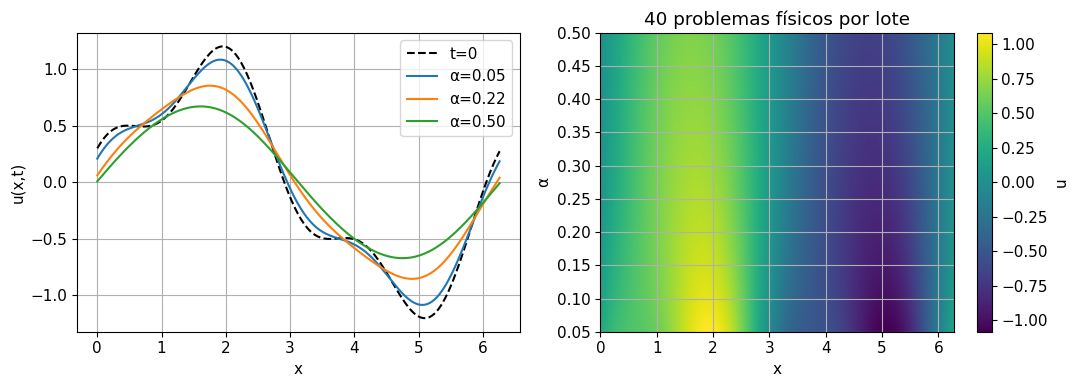

In [5]:
N, lote, t_final = 256, 40, 0.8
x = torch.arange(N, device=device, dtype=torch.float64)*(2*np.pi/N)
u0 = torch.sin(x)+0.3*torch.cos(3*x)
alpha = torch.linspace(0.05, 0.5, lote, device=device, dtype=torch.float64)
# d=1/N da índices de frecuencia enteros para dominio de longitud 2π.
modos = torch.fft.rfftfreq(N, d=1.0/N, device=device, dtype=torch.float64)
u_hat = torch.fft.rfft(u0)
uh_final = u_hat[None, :]*torch.exp(-alpha[:, None]*modos[None, :]**2*t_final)
uf = torch.fft.irfft(uh_final, n=N, dim=-1)
uex = torch.exp(-alpha[:, None]*t_final)*torch.sin(x)[None, :] + 0.3*torch.exp(-9*alpha[:, None]*t_final)*torch.cos(3*x)[None, :]
err = torch.max(torch.abs(uf-uex)).item()
print("Error máximo frente a solución exacta:", err)
assert err < 1e-10
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x.cpu().numpy(), u0.cpu().numpy(), "k--", label="t=0")
for j in [0, 15, 39]:
    axes[0].plot(x.cpu().numpy(), uf[j].cpu().numpy(), label=f"α={alpha[j].item():.2f}")
axes[0].set(xlabel="x", ylabel="u(x,t)"); axes[0].legend()
im = axes[1].imshow(uf.cpu().numpy(), origin="lower", aspect="auto", extent=[0, 2*np.pi, 0.05, 0.5])
axes[1].set(xlabel="x", ylabel="α", title="40 problemas físicos por lote")
fig.colorbar(im, ax=axes[1], label="u"); plt.tight_layout(); plt.show()

## 8. Diferenciación de un modelo físico

Si la solución depende de $\alpha$, podemos ajustar ese parámetro a observaciones. La derivada exacta para nuestro caso es
$$\partial_\alpha u=-t e^{-\alpha t}\sin x-2.7t e^{-9\alpha t}\cos3x.$$
Autograd registra operaciones con tensores que requieren gradiente. Una FFT y un producto diferenciables pueden formar parte de una pérdida. La capacidad de derivar el código no certifica por sí sola que la pérdida identifique un parámetro o que el solver sea preciso.

Antes de entrenar compararemos el gradiente de una pérdida con su expresión analítica. Es una comprobación científica pequeña y útil, especialmente al modificar el solver.

In [6]:
alpha_real = 0.24
observado = torch.exp(torch.tensor(-alpha_real*t_final, device=device))*torch.sin(x) + 0.3*torch.exp(torch.tensor(-9*alpha_real*t_final, device=device))*torch.cos(3*x)
a_param = torch.tensor(0.12, device=device, dtype=torch.float64, requires_grad=True)

def solucion(a):
    return torch.fft.irfft(u_hat*torch.exp(-a*modos**2*t_final), n=N)

u_pred = solucion(a_param)
loss = torch.mean((u_pred-observado)**2)
grad_auto = torch.autograd.grad(loss, a_param)[0]
du_da = -t_final*torch.exp(-a_param*t_final)*torch.sin(x)-2.7*t_final*torch.exp(-9*a_param*t_final)*torch.cos(3*x)
grad_exact = 2*torch.mean((u_pred-observado)*du_da)
print("Gradiente autograd:", grad_auto.item(), "Analítico:", grad_exact.item())
assert torch.allclose(grad_auto, grad_exact, rtol=1e-7, atol=1e-10)

Gradiente autograd: -0.12703063685685212 Analítico: -0.12703063685685212


## 9. Inferencia inversa sobre el dispositivo disponible

Para garantizar $\alpha>0$ usaremos $\alpha=\operatorname{softplus}(z)$. Esto convierte la restricción en una parametrización suave. El valor generador es conocido solo porque los datos son sintéticos.

El experimento ajusta un único parámetro de un solver diferenciable. No necesita una GPU para ser útil; su propósito es enseñar el mismo flujo de tensores, pérdida y gradientes que luego se aplica a redes o muchos problemas por lote. En problemas reales debemos añadir ruido, incertidumbre, regularización y datos de validación.

α final: 0.23998179122289542


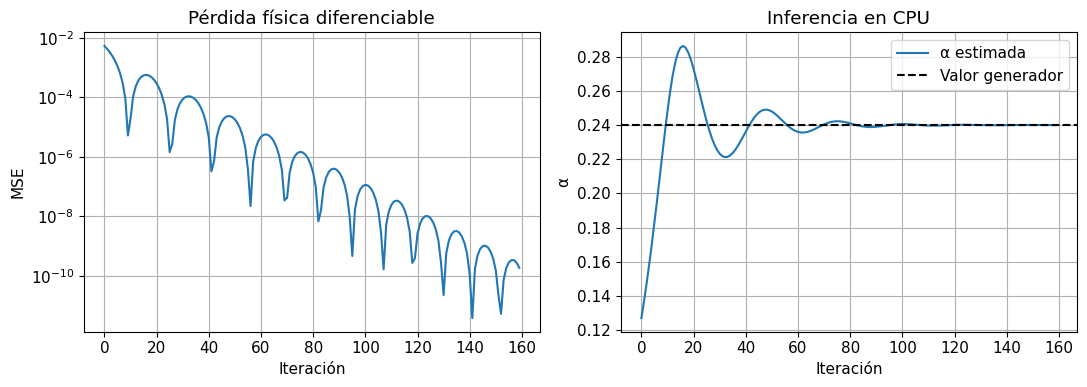

In [7]:
z = torch.tensor(-2.0, device=device, dtype=torch.float64, requires_grad=True)
optim = torch.optim.Adam([z], lr=0.08)
hist_loss, hist_alpha = [], []
for it in range(160):
    optim.zero_grad()
    aa = torch.nn.functional.softplus(z)
    perdida = torch.mean((solucion(aa)-observado)**2)
    perdida.backward(); optim.step()
    hist_loss.append(perdida.item()); hist_alpha.append(aa.item())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(hist_loss); axes[0].set(xlabel="Iteración", ylabel="MSE", title="Pérdida física diferenciable")
axes[1].plot(hist_alpha, label="α estimada")
axes[1].axhline(alpha_real, color="k", ls="--", label="Valor generador")
axes[1].set(xlabel="Iteración", ylabel="α", title=f"Inferencia en {device.type.upper()}")
axes[1].legend(); plt.tight_layout(); plt.show()
print("α final:", torch.nn.functional.softplus(z).item())

## 10. Memoria del grafo y del lote

Durante autograd pueden conservarse valores intermedios necesarios para derivar. Por eso entrenamiento suele consumir más memoria que inferencia. `torch.no_grad()` evita construir el grafo cuando solo necesitamos predicciones; no debe usarse si queremos derivadas físicas para una PINN.

Aumentar el lote mejora utilización hasta que memoria o ancho de banda limitan. Microbatches y acumulación de gradientes permiten repartir una pérdida, pero deben conservar su normalización: sumar pérdidas medias sin ponderar puede cambiar el objetivo si los grupos tienen tamaños distintos.

## 11. Reproducibilidad y límites

La semilla fija el muestreo de este ejemplo; distintas plataformas, versiones y kernels pueden cambiar resultados en los últimos bits. Algunas operaciones paralelas no tienen orden de reducción fijo. Para un resultado científico reporta tolerancias y compara cantidades físicas, no solamente igualdad de archivos.

Este cuaderno valida la ruta CPU y, si está disponible, CUDA. No demuestra rendimiento de GPUs que no estén presentes. Los datos sintéticos no contienen ruido de modelo y la solución de difusión se resuelve en Fourier, por lo que no evalúa dificultades de fronteras complejas o difusión no lineal.

## 12. Cuándo usar GPU en SciML

Una GPU puede ayudar con redes grandes, muchas condiciones iniciales, convoluciones, FFTs y operaciones diferenciables por lotes. Conviene mantener datos y modelo en el mismo dispositivo. Es menos claro el beneficio para una pequeña ODE individual con mucho control de flujo, o cuando la aplicación mueve resultados a CPU a cada paso.

La decisión se apoya en tres mediciones: precisión científica, memoria pico y tiempo extremo a extremo. El potencial teórico del hardware es una orientación; la aplicación real decide si amortiza su costo.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../18_HPC_COMPUTACION_CIENTIFICA/18_1_Performance.ipynb) | [⏩](../18_HPC_COMPUTACION_CIENTIFICA/18_3_Parallel_computing.ipynb) |